# Dimensionality Reduction with PCA and t-SNE

High-dimensional data is hard to visualise, expensive to store, and can make distance-based models
behave poorly. Dimensionality reduction projects data into a lower-dimensional space while preserving
as much useful structure as possible.

This notebook covers:

- **PCA** (Principal Component Analysis): a linear projection that maximises variance.
- **t-SNE**: a non-linear method for visualising local neighbourhoods.
- practical use of PCA inside a classification pipeline.

## Learning objectives

1. Explain what PCA optimises and why features must be centred/scaled first.
2. Read explained-variance ratios and choose the number of components.
3. Measure reconstruction error.
4. Use t-SNE correctly and interpret it cautiously.
5. Use PCA as a preprocessing step and compare predictive performance.

## 1. Concepts

### The curse of dimensionality

As the number of features grows, data becomes sparse in the feature space. Distances between points
become less informative, and models need exponentially more data to cover the space. Reducing
dimensions can improve speed, reduce noise, and help visualisation.

### PCA

PCA finds orthogonal directions (principal components) that maximise the variance of the projected data.

1. Centre the data (and usually scale it).
2. Compute the covariance matrix.
3. Compute its eigenvectors and eigenvalues.
4. Sort by eigenvalue; keep the top `k` components.

The explained-variance ratio of component `j` is:

$$\text{ratio}_j = \frac{\lambda_j}{\sum_i \lambda_i}$$

PCA is unsupervised: it does not look at the target. It preserves global variance, not necessarily
class separation.

### t-SNE

t-SNE converts high-dimensional distances into neighbour probabilities and finds a low-dimensional
embedding that matches them. It is excellent for visual exploration but:

- it is stochastic,
- it preserves local structure better than global distances,
- distances between clusters are not always meaningful,
- it is not a preprocessing step for supervised models.

## 2. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer, load_digits
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import TSNE
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid")

## 3. Explore PCA on the digits dataset

The digits dataset has 1,797 samples and 64 pixel features. We scale the features and inspect the
explained variance of the principal components.

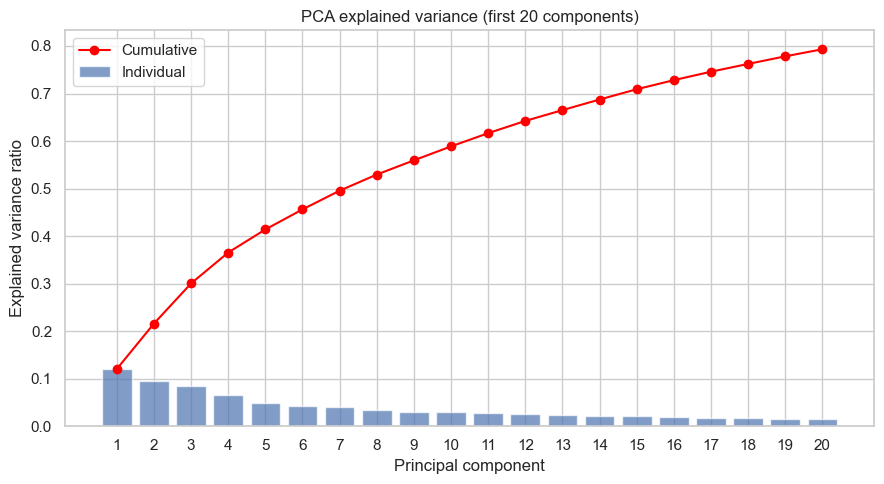

Components for 90% variance: 31
Components for 95% variance: 40
Components for 99% variance: 54


In [2]:
digits = load_digits(as_frame=True)
X_digits = digits.data
y_digits = digits.target

X_scaled = StandardScaler().fit_transform(X_digits)

pca_full = PCA(random_state=RANDOM_STATE).fit(X_scaled)
explained = pca_full.explained_variance_ratio_
cumulative = np.cumsum(explained)

plt.figure(figsize=(9, 5))
plt.bar(range(1, 21), explained[:20], alpha=0.7, label="Individual")
plt.plot(range(1, 21), cumulative[:20], marker="o", color="red", label="Cumulative")
plt.xlabel("Principal component")
plt.ylabel("Explained variance ratio")
plt.title("PCA explained variance (first 20 components)")
plt.xticks(range(1, 21))
plt.legend()
plt.tight_layout()
plt.show()

print("Components for 90% variance:", int(np.searchsorted(cumulative, 0.90) + 1))
print("Components for 95% variance:", int(np.searchsorted(cumulative, 0.95) + 1))
print("Components for 99% variance:", int(np.searchsorted(cumulative, 0.99) + 1))

### Project to two dimensions and visualise

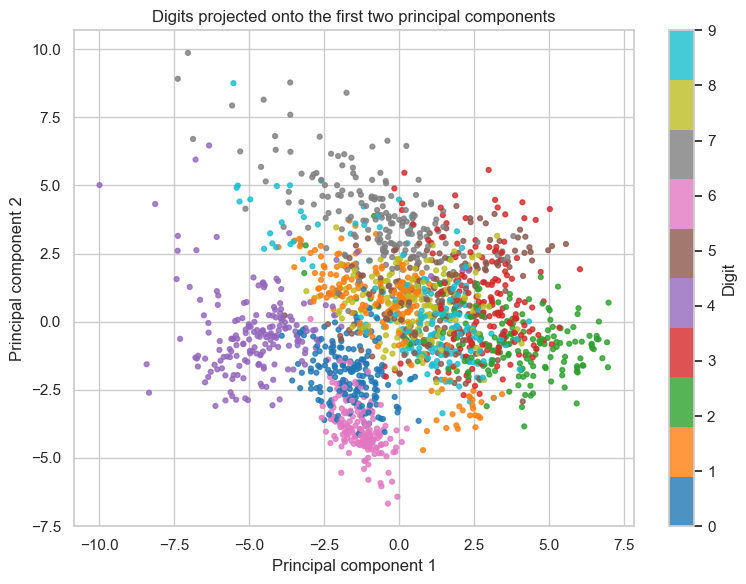

In [3]:
pca_2d = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca_2d = pca_2d.fit_transform(X_scaled)

plt.figure(figsize=(8, 6))
scatter = plt.scatter(X_pca_2d[:, 0], X_pca_2d[:, 1], c=y_digits, cmap="tab10", s=12, alpha=0.8)
plt.xlabel("Principal component 1")
plt.ylabel("Principal component 2")
plt.title("Digits projected onto the first two principal components")
plt.colorbar(scatter, label="Digit")
plt.tight_layout()
plt.show()

## 4. Reconstruction error

PCA can project data back to the original space. The reconstruction error decreases as more
components are kept. This is a useful way to choose a trade-off between compression and fidelity.

In [4]:
component_counts = [2, 5, 10, 20, 30, 40, 50, 64]
rows = []
for n in component_counts:
    pca = PCA(n_components=n, random_state=RANDOM_STATE)
    projected = pca.fit_transform(X_scaled)
    reconstructed = pca.inverse_transform(projected)
    mse = np.mean((X_scaled - reconstructed) ** 2)
    rows.append({"components": n, "reconstruction_mse": mse,
                 "explained_variance": pca.explained_variance_ratio_.sum()})

pd.DataFrame(rows).round(4)

,components,reconstruction_mse,explained_variance
0,2,0.7473,0.2159
1,5,0.5586,0.4140
2,10,0.3920,0.5887
3,20,0.1972,0.7931
4,30,0.1018,0.8932
5,40,0.0469,0.9508
6,50,0.0164,0.9828
7,64,0.0000,1.0000


## 5. PCA inside a classification pipeline

PCA can reduce noise and speed up a model, but it can also remove useful information. We compare a
logistic regression with and without PCA using cross-validation-like train/test evaluation.

In [5]:
cancer = load_breast_cancer(as_frame=True)
Xc, yc = cancer.data, cancer.target

Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    Xc, yc, test_size=0.25, random_state=RANDOM_STATE, stratify=yc
)

baseline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=5000, random_state=RANDOM_STATE)),
])
baseline.fit(Xc_train, yc_train)
print("No PCA:", round(accuracy_score(yc_test, baseline.predict(Xc_test)), 4))

rows = []
for n in [2, 4, 8, 12, 20]:
    pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("pca", PCA(n_components=n, random_state=RANDOM_STATE)),
        ("model", LogisticRegression(max_iter=5000, random_state=RANDOM_STATE)),
    ])
    pipe.fit(Xc_train, yc_train)
    rows.append({"components": n, "accuracy": accuracy_score(yc_test, pipe.predict(Xc_test))})

pd.DataFrame(rows).round(4)

No PCA: 0.986


,components,accuracy
0,2,0.9441
1,4,0.9650
2,8,0.9650
3,12,0.9720
4,20,0.9860


## 6. t-SNE on digits

t-SNE is computationally heavier, so we use a random subset. The result is a visual map of local
neighbourhoods, not a model input.

In [6]:
rng = np.random.default_rng(RANDOM_STATE)
indices = rng.choice(len(X_scaled), size=1000, replace=False)
X_subset = X_scaled[indices]
y_subset = y_digits.to_numpy()[indices]

tsne = TSNE(
    n_components=2,
    perplexity=30,
    learning_rate="auto",
    init="pca",
    random_state=RANDOM_STATE,
    max_iter=1000,
)
X_tsne = tsne.fit_transform(X_subset)
print("t-SNE embedding:", X_tsne.shape, "KL divergence:", round(tsne.kl_divergence_, 4))

t-SNE embedding: (1000, 2) KL divergence: 0.7144


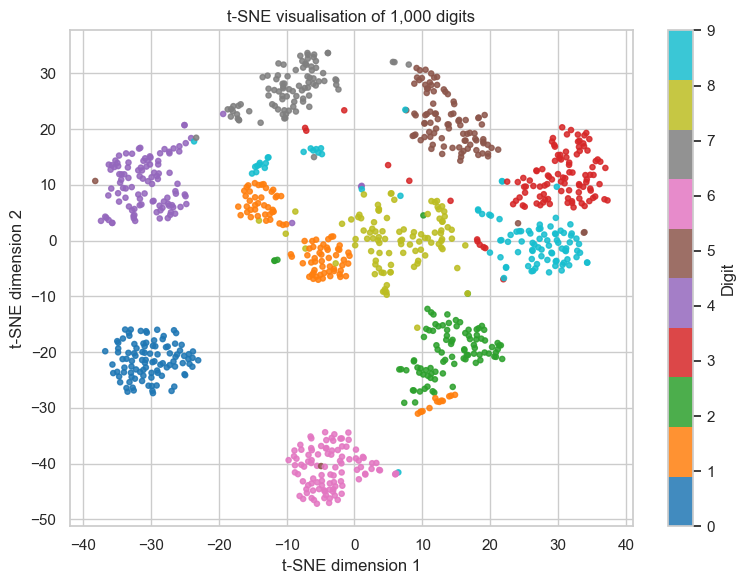

In [7]:
plt.figure(figsize=(8, 6))
scatter = plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=y_subset, cmap="tab10", s=14, alpha=0.85)
plt.xlabel("t-SNE dimension 1")
plt.ylabel("t-SNE dimension 2")
plt.title("t-SNE visualisation of 1,000 digits")
plt.colorbar(scatter, label="Digit")
plt.tight_layout()
plt.show()

### Interpreting t-SNE

- Nearby points have similar local neighbourhoods.
- The size and distance between clusters can change with `perplexity` and random seed.
- Do not use t-SNE coordinates as features for a supervised model.
- Use PCA first if the input has hundreds or thousands of dimensions; t-SNE is slow on raw high-dimensional data.

## Key takeaways

- PCA is a linear, unsupervised compression method based on variance.
- Scale features before PCA; otherwise large-scale features dominate.
- Keep enough components to preserve the variance your application needs.
- t-SNE is for visualisation, not feature engineering.
- Always compare a reduced model with a baseline on held-out data.

## Exercises

1. Run PCA without scaling on the digits data. How does the explained-variance plot change?
2. Use `PCA(whiten=True)` and compare classification accuracy.
3. Try t-SNE with `perplexity=5` and `perplexity=50`. What changes?
4. Use PCA to compress the breast-cancer data to 2D and plot the classes. Are they separable?
5. Explain why PCA can hurt a classifier even when it preserves most of the variance.